In [ ]:
train_dir =r'/new_road_Dataset/train'
test_dir=r'/new_road_Dataset/test'

In [ ]:
import tensorflow as tf
from tensorflow.keras import initializers
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import random
seed=14
np.random.seed=seed
img_width=512
img_height=512
img_channels=3

In [ ]:
train_img_dir = os.path.join(train_dir,'images/')
train_mask_dir = os.path.join(train_dir,'masks/')
test_img_dir = os.path.join(test_dir,'images/')
test_mask_dir = os.path.join(test_dir,'masks/')

In [ ]:
print(train_img_dir)
test_img_count = len(os.listdir(test_img_dir))
train_img_count=len(os.listdir(train_img_dir))
train_img_ids = os.listdir(train_img_dir)
test_img_ids = os.listdir(test_img_dir)
train_mask_count=len(os.listdir(train_mask_dir))
train_mask_ids=os.listdir(train_mask_dir)
print('Train image count is',train_img_count,'and their ids are',train_img_ids)
print('Mask image count is',train_mask_count,'and theur ids are',train_mask_ids)

/content/drive/MyDrive/new_road_Dataset/train/images/
Train image count is 198 and their ids are ['img-131.png', 'img-120.png', 'img-123.png', 'img-143.png', 'img-133.png', 'img-126.png', 'img-128.png', 'img-150.png', 'img-119.png', 'img-147.png', 'img-142.png', 'img-149.png', 'img-148.png', 'img-113.png', 'img-107.png', 'img-144.png', 'img-111.png', 'img-114.png', 'img-135.png', 'img-104.png', 'img-116.png', 'img-125.png', 'img-141.png', 'img-146.png', 'img-132.png', 'img-140.png', 'img-137.png', 'img-13.png', 'img-136.png', 'img-1.png', 'img-127.png', 'img-118.png', 'img-138.png', 'img-152.png', 'img-100.png', 'img-108.png', 'img-14.png', 'img-151.png', 'img-130.png', 'img-112.png', 'img-106.png', 'img-102.png', 'img-139.png', 'img-145.png', 'img-103.png', 'img-109.png', 'img-134.png', 'img-15.png', 'img-117.png', 'img-105.png', 'img-10.png', 'img-110.png', 'img-12.png', 'img-121.png', 'img-129.png', 'img-11.png', 'img-101.png', 'img-124.png', 'img-153.png', 'img-115.png', 'img-122.p

In [ ]:
test_img_count=len(os.listdir(test_img_dir))
test_img_ids=os.listdir(test_img_dir)

In [ ]:
test_img_count = len(os.listdir(test_img_dir))
test_img_ids = os.listdir(test_img_dir)
print('Test image count is',test_img_count,'and their ids are',test_img_ids)

Test image count is 6 and their ids are ['img-2.png', 'img-4.png', 'img-3.png', 'img-1.png', 'img-6.png', 'img-5.png']


In [ ]:
X_train = np.zeros((train_mask_count,img_width,img_height,img_channels),dtype=np.uint8)
y_train = np.zeros((len(train_mask_ids),img_width,img_height,1),dtype=np.bool_)

In [ ]:
print('Resizing train images and masks')
for n,img_name in tqdm(enumerate(train_mask_ids),total=len(train_mask_ids)):
    path = train_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_train[n] = img
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(train_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_train[n] = mask

Resizing train images and masks


100%|██████████| 198/198 [03:05<00:00,  1.06it/s]


In [ ]:
X_test = np.zeros((test_img_count,img_width,img_height,img_channels),dtype=np.uint8)
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)


In [ ]:
print('Resizing test images')
for i,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    path = test_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_test[i] = img

Resizing test images


100%|██████████| 6/6 [00:04<00:00,  1.25it/s]


In [ ]:
print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 6/6 [00:04<00:00,  1.22it/s]


In [ ]:
input_shape = (img_height, img_width, img_channels)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import vgg19


In [ ]:
'''
class DirectionalAttention(layers.Layer):
    def __init__(self, filters):
        super().__init__()
        self.conv_0 = layers.Conv2D(filters, (1, 7), padding='same')
        self.conv_45 = layers.Conv2D(filters, (3, 3), padding='same')
        self.conv_90 = layers.Conv2D(filters, (7, 1), padding='same')
        self.conv_135 = layers.Conv2D(filters, (3, 3), padding='same')
        self.alpha = self.add_weight(
            shape=(4,),
            initializer="ones",
            trainable=True
        )

    def call(self, x):
        f0 = self.conv_0(x)
        f45 = self.conv_45(x)
        f90 = self.conv_90(x)
        f135 = self.conv_135(x)

        out = (
            self.alpha[0] * f0 +
            self.alpha[1] * f45 +
            self.alpha[2] * f90 +
            self.alpha[3] * f135
        )
        return out
'''

'\nclass DirectionalAttention(layers.Layer):\n    def __init__(self, filters):\n        super().__init__()\n        self.conv_0 = layers.Conv2D(filters, (1, 7), padding=\'same\')\n        self.conv_45 = layers.Conv2D(filters, (3, 3), padding=\'same\')\n        self.conv_90 = layers.Conv2D(filters, (7, 1), padding=\'same\')\n        self.conv_135 = layers.Conv2D(filters, (3, 3), padding=\'same\')\n        self.alpha = self.add_weight(\n            shape=(4,),\n            initializer="ones",\n            trainable=True\n        )\n\n    def call(self, x):\n        f0 = self.conv_0(x)\n        f45 = self.conv_45(x)\n        f90 = self.conv_90(x)\n        f135 = self.conv_135(x)\n\n        out = (\n            self.alpha[0] * f0 +\n            self.alpha[1] * f45 +\n            self.alpha[2] * f90 +\n            self.alpha[3] * f135\n        )\n        return out\n'

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers


class DirectionalAttention(layers.Layer):
    def __init__(self, filters, **kwargs):
        super().__init__(**kwargs)

        self.filters = filters

        # Four directional convolution branches
        self.conv_0 = layers.Conv2D(
            filters, (1, 7), padding="same", use_bias=False
        )
        self.conv_45 = layers.Conv2D(
            filters, (7, 7), padding="same", use_bias=False
        )
        self.conv_90 = layers.Conv2D(
            filters, (7, 1), padding="same", use_bias=False
        )
        self.conv_135 = layers.Conv2D(
            filters, (7, 7), padding="same", use_bias=False
        )

        self.alpha = self.add_weight(
            name="direction_weights",
            shape=(4,),
            initializer="ones",
            trainable=True
        )

    def build(self, input_shape):
        # Explicitly build all convolution layers first
        self.conv_0.build(input_shape)
        self.conv_45.build(input_shape)
        self.conv_90.build(input_shape)
        self.conv_135.build(input_shape)

        # Main-diagonal and anti-diagonal masks
        main_diag = tf.eye(7, dtype=tf.float32)
        anti_diag = tf.reverse(main_diag, axis=[1])

        # Broadcast across input and output channels
        in_channels = int(input_shape[-1])
        self.mask_45 = tf.reshape(
            main_diag, (7, 7, 1, 1)
        )
        self.mask_135 = tf.reshape(
            anti_diag, (7, 7, 1, 1)
        )

        super().build(input_shape)

    def call(self, x):
        f0 = self.conv_0(x)
        f90 = self.conv_90(x)

        # Apply diagonal masks to the built convolution kernels
        kernel_45 = self.conv_45.kernel * self.mask_45
        kernel_135 = self.conv_135.kernel * self.mask_135

        f45 = tf.nn.conv2d(
            x, kernel_45,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )
        f135 = tf.nn.conv2d(
            x, kernel_135,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

        # Softmax-normalized directional fusion
        alpha = tf.nn.softmax(self.alpha)

        out = (
            alpha[0] * f0 +
            alpha[1] * f45 +
            alpha[2] * f90 +
            alpha[3] * f135
        )

        return out

    def get_config(self):
        config = super().get_config()
        config.update({"filters": self.filters})
        return config


In [ ]:

class TransformerBlock(layers.Layer):
    def __init__(self, dim, num_heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = layers.LayerNormalization()
        self.attn = layers.MultiHeadAttention(num_heads, key_dim=dim)
        self.norm2 = layers.LayerNormalization()
        self.mlp = tf.keras.Sequential([
            layers.Dense(dim * mlp_ratio, activation='gelu'),
            layers.Dense(dim)
        ])

    def call(self, x):
        h = x
        x = self.norm1(x)
        x = self.attn(x, x)
        x = h + x

        h = x
        x = self.norm2(x)
        x = self.mlp(x)
        return h + x


In [ ]:
def hybrid_bottleneck(x, filters):
    b, h, w, c = x.shape
    x_flat = layers.Reshape((h * w, c))(x)

    x_trans = TransformerBlock(c)(x_flat)
    x_trans = layers.Reshape((h, w, c))(x_trans)

    x = layers.Concatenate()([x, x_trans])
    x = layers.Conv2D(filters, 1, activation='relu')(x)
    x=layers.BatchNormalization()(x)
    return x


In [ ]:
def decoder_block(x, skip, filters):
    x = layers.UpSampling2D()(x)
    x = layers.Concatenate()([x, skip])

    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    return x

In [ ]:
# def decoder_block(x, skip, filters):
#     x = layers.UpSampling2D()(x)
#     x = layers.Concatenate()([x, skip])
#     x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
#     x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
#     return x


In [ ]:
def TopoRoadNet(input_shape=(512, 512, 3)):
    inputs = layers.Input(input_shape)

    # Encoder (ResNet)
    base = vgg19.VGG19(include_top=False, weights='imagenet', input_tensor=inputs)

    e1 = base.get_layer("block1_conv2").output # Use a suitable layer from VGG19, 'conv1_relu' is not a VGG19 layer name
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    # Directional Attention
    e4 = DirectionalAttention(512)(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, 512)

    # Decoder
    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    # The previous UpSampling2D was causing the output to be 1024x1024.
    # d2 is already 512x512, so it can directly feed into the final convolution.
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d2)

    return models.Model(inputs, outputs, name="TopoRoadNet")

In [ ]:
X_train = X_train.astype("float32")
X_test  = X_test.astype("float32")

# Normalize if needed
if X_train.max() > 1.0:
    X_train /= 255.0
    X_test  /= 255.0


In [ ]:
if y_train.ndim == 3:
    y_train = np.expand_dims(y_train, axis=-1)

if y_test_ground_truth.ndim == 3:
    y_test_ground_truth = np.expand_dims(y_test_ground_truth, axis=-1)

y_train = y_train.astype("float32")
y_test_ground_truth = y_test_ground_truth.astype("float32")

In [ ]:
model = TopoRoadNet(input_shape=X_train.shape[1:])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
#     loss=total_loss,
#     metrics=[
#         tf.keras.metrics.BinaryAccuracy(name="accuracy"),
#         tf.keras.metrics.MeanIoU(num_classes=2, name="IoU")
#     ]
# )

model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "TopoRoadNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 512, 512,  │      1,792 │ input_layer[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 512, 512,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 256, 256,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 256, 256,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 256, 256,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 128, 128,  │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 128, 128,  │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 128, 128,  │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 128, 128,  │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv4        │ (None, 128, 128,  │    590,080 │ block3_conv3[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 64, 64,    │          0 │ block3_conv4[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 64, 64,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 64, 64,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 64, 64,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv4        │ (None, 64, 64,    │  2,359,808 │ block4_conv3[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ directional_attent… │ (None, 64, 64,    │ 29,360,132 │ block4_conv4[0][

 Total params: 54,075,525 (206.28 MB)

 Trainable params: 54,072,709 (206.27 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet_best.h5",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]


In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,   # 80% train, 20% validation
    batch_size=4,
    epochs=100,
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7890 - loss: 0.4718   
Epoch 1: val_loss improved from None to 0.73277, saving model to toporoadnet_best.h5



Epoch 1: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 222s 3s/step - accuracy: 0.8819 - loss: 0.3362 - val_accuracy: 0.6540 - val_loss: 0.7328 - learning_rate: 1.0000e-04
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9545 - loss: 0.1693
Epoch 2: val_loss improved from 0.73277 to 0.44001, saving model to toporoadnet_best.h5



Epoch 2: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9581 - loss: 0.1547 - val_accuracy: 0.8327 - val_loss: 0.4400 - learning_rate: 1.0000e-04
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9642 - loss: 0.1253
Epoch 3: val_loss improved from 0.44001 to 0.23659, saving model to toporoadnet_best.h5



Epoch 3: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9657 - loss: 0.1221 - val_accuracy: 0.9680 - val_loss: 0.2366 - learning_rate: 1.0000e-04
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9683 - loss: 0.1111
Epoch 4: val_loss improved from 0.23659 to 0.15141, saving model to toporoadnet_best.h5



Epoch 4: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 224ms/step - accuracy: 0.9697 - loss: 0.1069 - val_accuracy: 0.9710 - val_loss: 0.1514 - learning_rate: 1.0000e-04
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9732 - loss: 0.0964
Epoch 5: val_loss improved from 0.15141 to 0.11274, saving model to toporoadnet_best.h5


...


Epoch 19: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9841 - loss: 0.0508 - val_accuracy: 0.9805 - val_loss: 0.0617 - learning_rate: 1.0000e-04
Epoch 20/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9854 - loss: 0.0476
Epoch 20: val_loss did not improve from 0.06173
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 187ms/step - accuracy: 0.9848 - loss: 0.0484 - val_accuracy: 0.9784 - val_loss: 0.0652 - learning_rate: 1.0000e-04
Epoch 21/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9859 - loss: 0.0456
Epoch 21: val_loss improved from 0.06173 to 0.06082, saving model to toporoadnet_best.h5



Epoch 21: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 224ms/step - accuracy: 0.9858 - loss: 0.0456 - val_accuracy: 0.9808 - val_loss: 0.0608 - learning_rate: 1.0000e-04
Epoch 22/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9863 - loss: 0.0443
Epoch 22: val_loss did not improve from 0.06082
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 187ms/step - accuracy: 0.9855 - loss: 0.0460 - val_accuracy: 0.9762 - val_loss: 0.0728 - learning_rate: 1.0000e-04
Epoch 23/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9842 - loss: 0.0483
Epoch 23: val_loss did not improve from 0.06082
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 187ms/step - accuracy: 0.9843 - loss: 0.0477 - val_accuracy: 0.9792 - val_loss: 0.0610 - learning_rate: 1.0000e-04
Epoch 24/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9857 - loss: 0.0445
Epoch 24: val_loss improved from 0.06082 to 0.06005, saving model to toporoadnet_best.h5



Epoch 24: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 223ms/step - accuracy: 0.9856 - loss: 0.0443 - val_accuracy: 0.9798 - val_loss: 0.0600 - learning_rate: 1.0000e-04
Epoch 25/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9870 - loss: 0.0406
Epoch 25: val_loss improved from 0.06005 to 0.05877, saving model to toporoadnet_best.h5



Epoch 25: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 223ms/step - accuracy: 0.9870 - loss: 0.0406 - val_accuracy: 0.9807 - val_loss: 0.0588 - learning_rate: 1.0000e-04
Epoch 26/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9882 - loss: 0.0381
Epoch 26: val_loss improved from 0.05877 to 0.05743, saving model to toporoadnet_best.h5



Epoch 26: finished saving model to toporoadnet_best.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 226ms/step - accuracy: 0.9870 - loss: 0.0401 - val_accuracy: 0.9806 - val_loss: 0.0574 - learning_rate: 1.0000e-04
Epoch 27/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9888 - loss: 0.0364
Epoch 27: val_loss did not improve from 0.05743
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 187ms/step - accuracy: 0.9885 - loss: 0.0366 - val_accuracy: 0.9805 - val_loss: 0.0592 - learning_rate: 1.0000e-04
Epoch 28/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9888 - loss: 0.0354
Epoch 28: val_loss did not improve from 0.05743
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 187ms/step - accuracy: 0.9888 - loss: 0.0353 - val_accuracy: 0.9804 - val_loss: 0.0588 - learning_rate: 1.0000e-04
Epoch 29/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9895 - loss: 0.0336
Epoch 29: val_loss did not improve from 0.05743
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 187ms/step - accuracy: 0.9896 - loss: 0.0333 - val_accuracy: 0.9807 - v

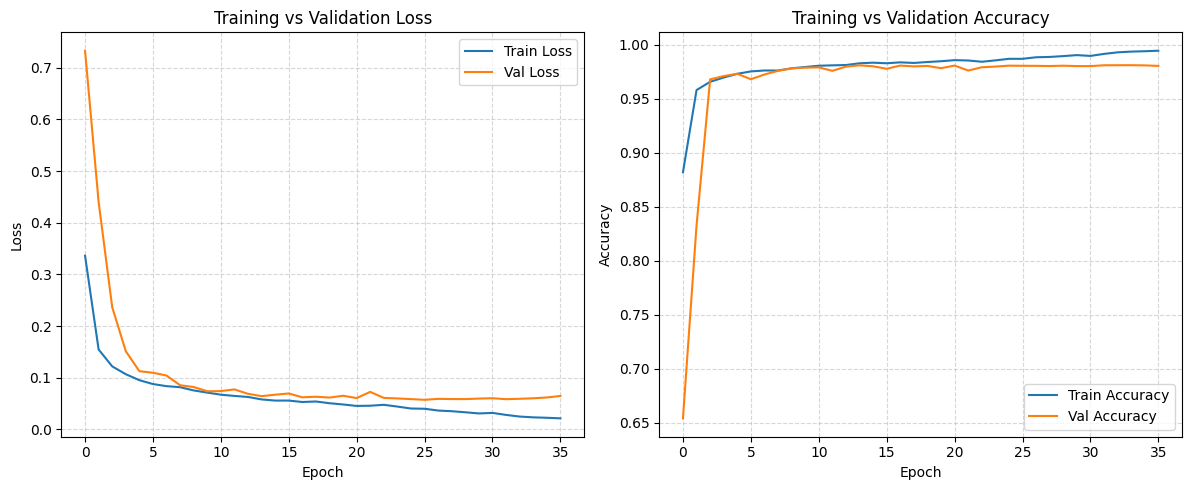

In [ ]:
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(18, 5))

# ---- LOSS ----
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# ---- ACCURACY ----
plt.subplot(1, 3, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# ---- IoU ----

plt.tight_layout()
plt.show()


In [ ]:
test_results = model.evaluate(
    X_test,
    y_test_ground_truth,
    batch_size=4,
    verbose=1
)

print("Test Loss:", test_results[0])
print("Test Accuracy:", test_results[1])
#print("Test IoU:", test_results[2])


2/2 ━━━━━━━━━━━━━━━━━━━━ 16s 11s/step - accuracy: 0.9469 - loss: 0.1433
Test Loss: 0.14326228201389313
Test Accuracy: 0.9469273686408997


In [ ]:
Y_pred = model.predict(X_test, batch_size=4)
Y_pred_bin = (Y_pred > 0.3).astype("uint8")


2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 5s/step


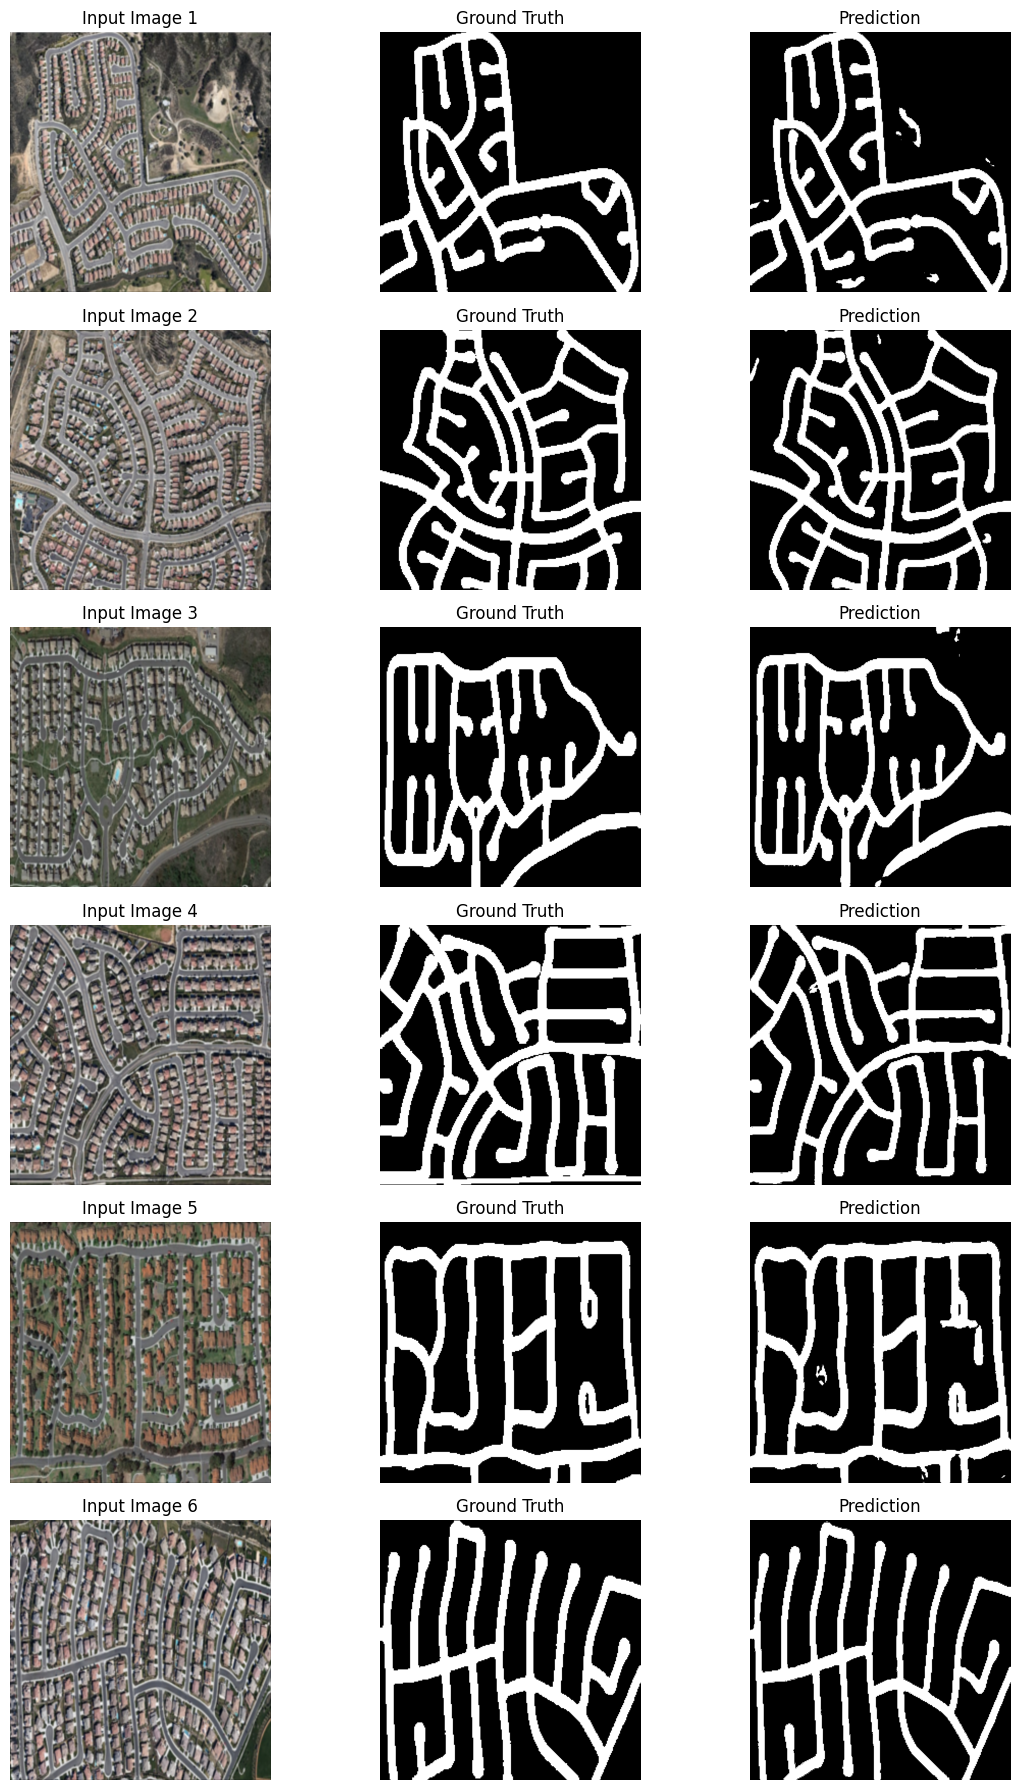

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

num_images = 6
indices = np.random.choice(len(X_test), num_images, replace=False)

plt.figure(figsize=(12, num_images * 3))

for i, idx in enumerate(indices):
    # Input Image
    plt.subplot(num_images, 3, i*3 + 1)
    plt.imshow(X_test[idx])
    plt.title(f"Input Image {i+1}")
    plt.axis("off")

    # Ground Truth
    plt.subplot(num_images, 3, i*3 + 2)
    plt.imshow(y_test_ground_truth[idx].squeeze(), cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    # Prediction
    plt.subplot(num_images, 3, i*3 + 3)
    plt.imshow(Y_pred_bin[idx].squeeze(), cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
def overlay_mask(image, mask, alpha=0.5):
    overlay = image.copy()
    overlay[mask.squeeze() == 1] = [1.0, 0.0, 0.0]  # Red roads
    return (1 - alpha) * image + alpha * overlay


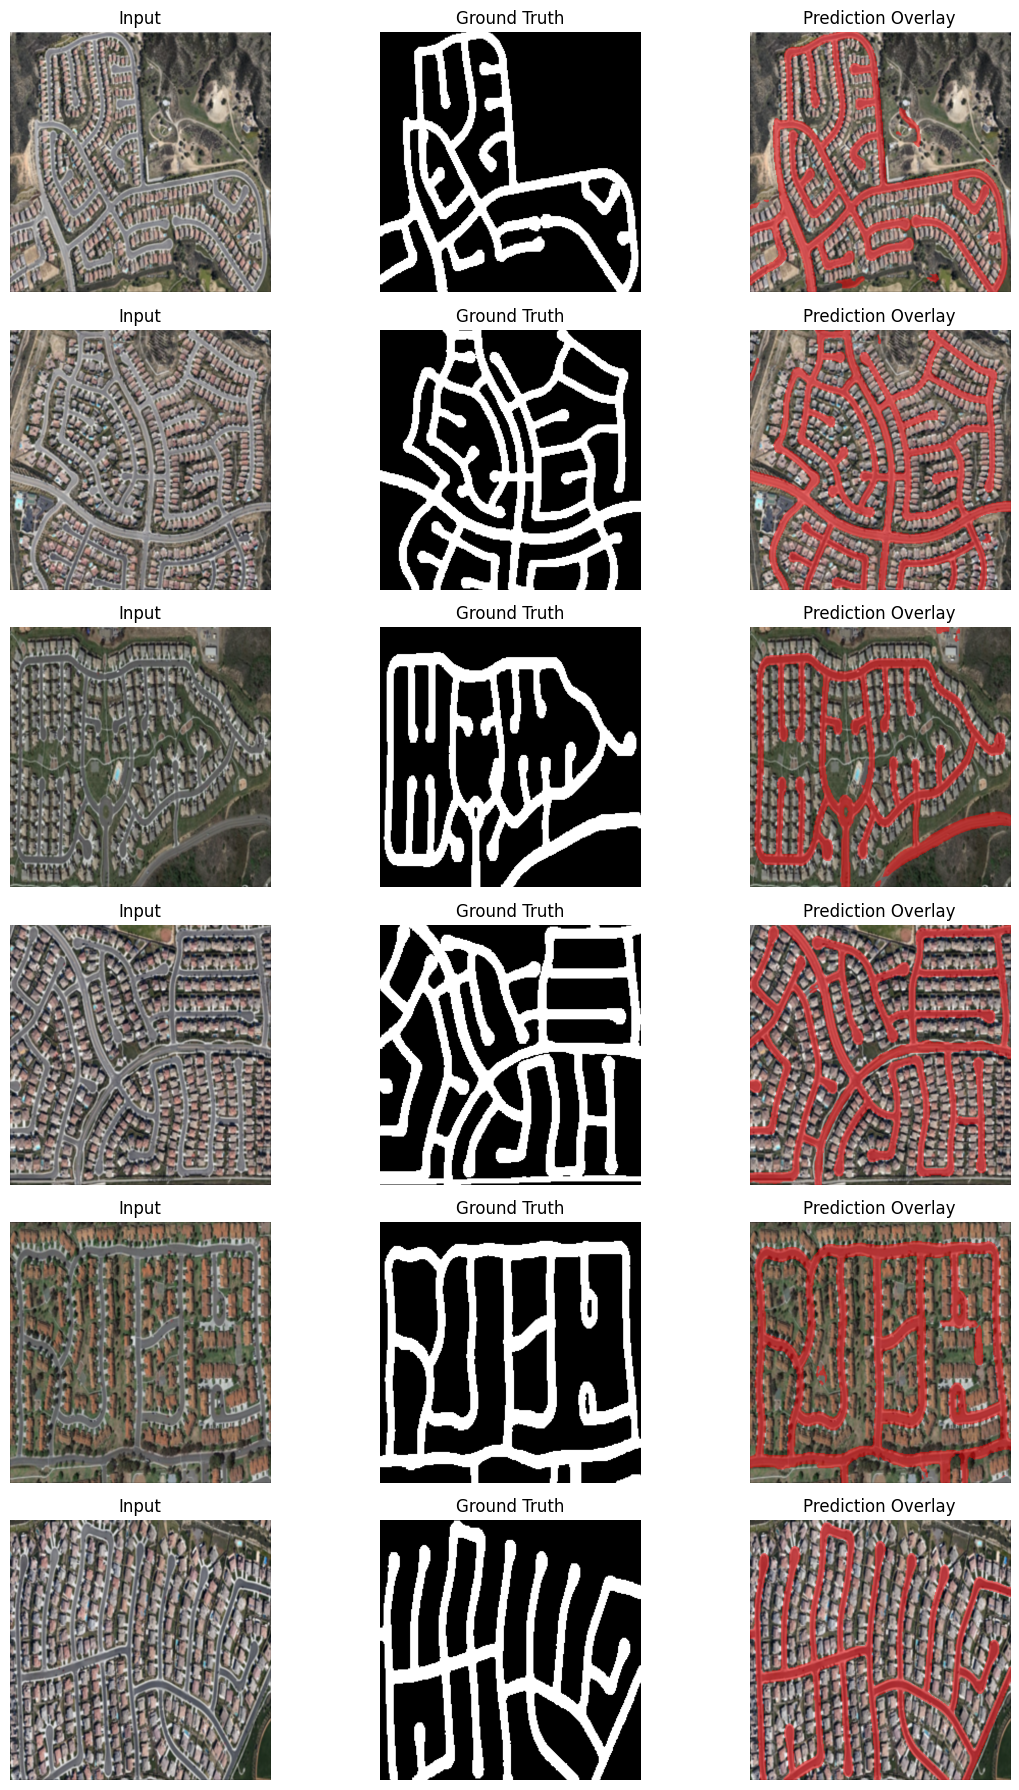

In [ ]:
plt.figure(figsize=(12, num_images * 3))

for i, idx in enumerate(indices):
    overlay_img = overlay_mask(X_test[idx], Y_pred_bin[idx])

    plt.subplot(num_images, 3, i*3 + 1)
    plt.imshow(X_test[idx])
    plt.title("Input")
    plt.axis("off")

    plt.subplot(num_images, 3, i*3 + 2)
    plt.imshow(y_test_ground_truth[idx].squeeze(), cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_images, 3, i*3 + 3)
    plt.imshow(overlay_img)
    plt.title("Prediction Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

# Flatten arrays
y_true = y_test_ground_truth.flatten().astype(np.uint8)
y_pred = Y_pred_bin.flatten().astype(np.uint8)

# Confusion matrix components
TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

# Metrics
precision = TP / (TP + FP + 1e-8)
recall    = TP / (TP + FN + 1e-8)
f1_score  = 2 * precision * recall / (precision + recall + 1e-8)
iou       = TP / (TP + FP + FN + 1e-8)
accuracy  = (TP + TN) / (TP + TN + FP + FN)

# Cohen's Kappa
total = TP + TN + FP + FN
po = accuracy
pe = (((TP + FP) * (TP + FN)) + ((FN + TN) * (FP + TN))) / (total ** 2)
kappa = (po - pe) / (1 - pe + 1e-8)

# Print results
print("===== PIXEL-LEVEL EVALUATION METRICS =====")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-score        : {f1_score:.4f}")
print(f"IoU             : {iou:.4f}")
print(f"Overall Accuracy: {accuracy:.4f}")
print(f"Kappa (κ)       : {kappa:.4f}")
print("=========================================")


===== PIXEL-LEVEL EVALUATION METRICS =====
Precision       : 0.9767
Recall          : 0.8701
F1-score        : 0.9203
IoU             : 0.8524
Overall Accuracy: 0.9556
Kappa (κ)       : 0.8897


1/1 ━━━━━━━━━━━━━━━━━━━━ 38s 38s/step
===== PIXEL-LEVEL EVALUATION METRICS =====
Precision       : 0.9709
Recall          : 0.8923
F1-score        : 0.9300
IoU             : 0.8691
Overall Accuracy: 0.9604
Kappa (κ)       : 0.9024



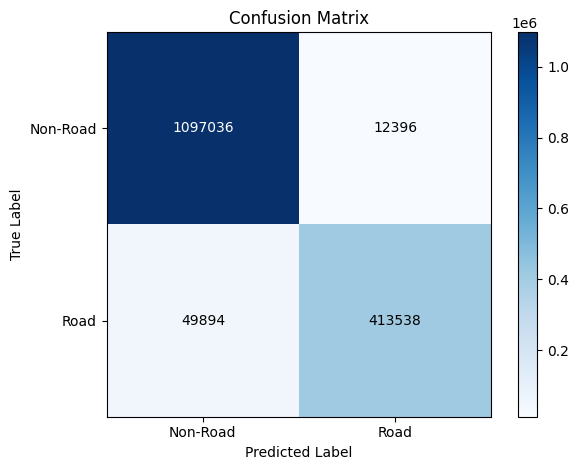

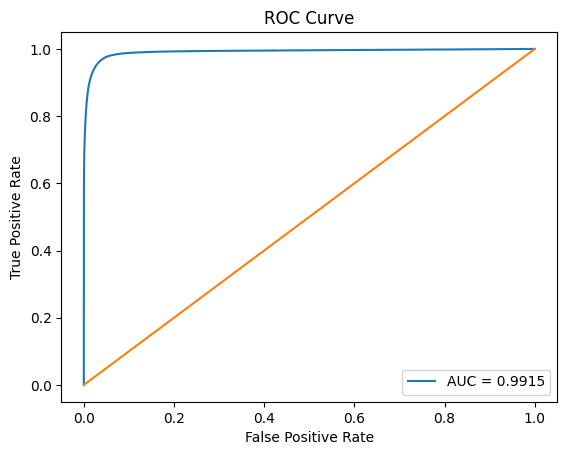

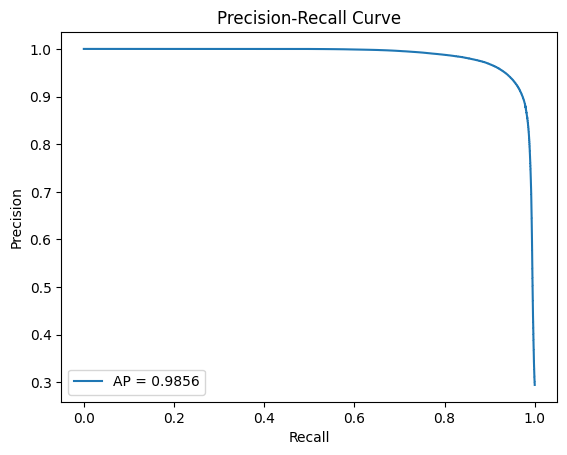

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

Y_pred_prob = model.predict(X_test)

# Flatten
y_true = y_test_ground_truth.flatten().astype(np.uint8)
y_scores = Y_pred_prob.flatten()

# Binary threshold
Y_pred_bin = (Y_pred_prob > 0.2).astype(np.uint8)
y_pred = Y_pred_bin.flatten()# ===============================
# Confusion Matrix Components
# ===============================
TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

precision = TP / (TP + FP + 1e-8)
recall    = TP / (TP + FN + 1e-8)
f1_score  = 2 * precision * recall / (precision + recall + 1e-8)
iou       = TP / (TP + FP + FN + 1e-8)
accuracy  = (TP + TN) / (TP + TN + FP + FN)

total = TP + TN + FP + FN
po = accuracy
pe = (((TP + FP) * (TP + FN)) + ((FN + TN) * (FP + TN))) / (total ** 2)
kappa = (po - pe) / (1 - pe + 1e-8)

print("===== PIXEL-LEVEL EVALUATION METRICS =====")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-score        : {f1_score:.4f}")
print(f"IoU             : {iou:.4f}")
print(f"Overall Accuracy: {accuracy:.4f}")
print(f"Kappa (κ)       : {kappa:.4f}")
print("=========================================\n")

# ===============================
# 1️⃣ Confusion Matrix (White-Blue)
# ===============================
cm = confusion_matrix(y_true, y_pred)

plt.figure()
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()

classes = ["Non-Road", "Road"]
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, f"{cm[i, j]}",
                 ha="center",
                 va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.tight_layout()
plt.show()


# ===============================
# 2️⃣ ROC Curve
# ===============================
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# ===============================
# 3️⃣ Precision-Recall Curve
# ===============================
precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall_vals, precision_vals)

plt.figure()
plt.plot(recall_vals, precision_vals, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

Tuning on validation images...
  thr=0.30 gap= 0 spur= 0 -> val APLS 0.7677
  thr=0.30 gap= 0 spur=10 -> val APLS 0.7667
  thr=0.30 gap=20 spur= 0 -> val APLS 0.7724
  thr=0.30 gap=20 spur=10 -> val APLS 0.7719
  thr=0.40 gap= 0 spur= 0 -> val APLS 0.7775
  thr=0.40 gap= 0 spur=10 -> val APLS 0.7727
  thr=0.40 gap=20 spur= 0 -> val APLS 0.7800
  thr=0.40 gap=20 spur=10 -> val APLS 0.7760
  thr=0.50 gap= 0 spur= 0 -> val APLS 0.7559
  thr=0.50 gap= 0 spur=10 -> val APLS 0.7554
  thr=0.50 gap=20 spur= 0 -> val APLS 0.7566
  thr=0.50 gap=20 spur=10 -> val APLS 0.7555
Best settings: {'thr': 0.4, 'max_gap': 20, 'spur': 0}  (val APLS 0.7800)

Image 001 - APLS: 0.7396
Image 002 - APLS: 0.7038
Image 003 - APLS: 0.5819
Image 004 - APLS: 0.5576
Image 005 - APLS: 0.6836
Image 006 - APLS: 0.5950

=========== APLS SUMMARY (TEST) ===========
Settings         : {'thr': 0.4, 'max_gap': 20, 'spur': 0}
Images evaluated : 6 / 6
Mean APLS        : 0.6436
Median APLS      : 0.6393
Std              : 0.0683

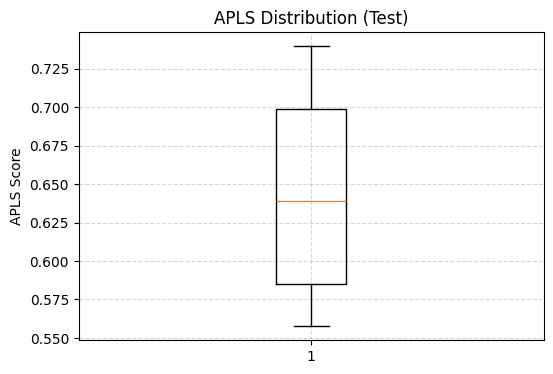

In [ ]:
# ============ APLS EVALUATION: improved, single cell ============
# Needs: model, X_test, y_test_ground_truth, X_train, y_train

import numpy as np, networkx as nx, random, itertools, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.ndimage import convolve
from skimage.morphology import skeletonize, remove_small_objects, binary_closing, disk
from skimage.measure import label
from skimage.draw import line

# ---------------- Settings ----------------
USE_TTA   = True            # 8x flip/rotate averaging (slower, better)
TUNE      = True            # tune postprocessing on VALIDATION data (not test)
N_VAL     = 20              # validation images used for tuning
GRID_THR  = (0.3, 0.4, 0.5)
GRID_GAP  = (0, 20)         # max gap (px) to bridge
GRID_SPUR = (0, 10)         # spur length (px) to prune
DEFAULT   = dict(thr=0.4, max_gap=20, spur=10)   # used if TUNE=False
MIN_SIZE, CLOSE_R = 150, 2
BUFFER, N_NODES, SEED = 4, 60, 42

# ---------------- Prediction (optional TTA) ----------------
def predict_probs(X, bs=4):
    if not USE_TTA:
        return model.predict(X, batch_size=bs, verbose=0)
    out = np.zeros(X.shape[:3] + (1,), np.float32)
    for k in range(4):
        for flip in (False, True):
            x = np.rot90(X, k, axes=(1, 2))
            if flip: x = x[:, :, ::-1]
            p = model.predict(np.ascontiguousarray(x), batch_size=bs, verbose=0)
            if flip: p = p[:, :, ::-1]
            out += np.rot90(p, -k, axes=(1, 2))
    return out / 8.0

# ---------------- Mask -> skeleton -> graph ----------------
def bridge_gaps(skel, max_gap):
    if max_gap <= 0: return skel
    skel = skel.copy()
    pts = np.argwhere(skel)
    if len(pts) < 2: return skel
    lab = label(skel, connectivity=2)
    nb = convolve(skel.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant") - 1
    ends = np.argwhere(skel & (nb == 1))
    tree = cKDTree(pts)
    kq = min(100, len(pts))
    for y, x in ends:
        d, j = tree.query([y, x], k=kq, distance_upper_bound=max_gap)
        for dd, jj in zip(np.atleast_1d(d), np.atleast_1d(j)):
            if np.isinf(dd): break
            py, px = pts[jj]
            if lab[py, px] != lab[y, x]:           # different component -> connect
                rr, cc = line(y, x, py, px); skel[rr, cc] = True
                break
    return skeletonize(skel)

def pred_to_skeleton(prob, thr, max_gap):
    m = prob.squeeze() > thr
    if CLOSE_R > 0: m = binary_closing(m, disk(CLOSE_R))
    if MIN_SIZE > 0: m = remove_small_objects(m, MIN_SIZE)
    return bridge_gaps(skeletonize(m), max_gap)

def skel_to_graph(skel):
    pts = set(map(tuple, np.argwhere(skel)[:, ::-1]))      # (x, y)
    G = nx.Graph(); G.add_nodes_from(pts)
    for (x, y) in pts:
        for dx, dy in ((1, 0), (0, 1), (1, 1), (1, -1)):   # each pair once
            q = (x + dx, y + dy)
            if q in pts: G.add_edge((x, y), q, weight=float(np.hypot(dx, dy)))
    return G

def prune_spurs(G, min_len):
    if min_len <= 0: return G
    G = G.copy()
    for n in [n for n in G.nodes if G.degree(n) == 1]:
        if n not in G: continue
        path, cur, prev = [n], n, None
        while True:
            nxt = [m for m in G.neighbors(cur) if m != prev]
            if len(nxt) != 1: break
            prev, cur = cur, nxt[0]; path.append(cur)
            if G.degree(cur) != 2: break
        if G.degree(cur) >= 3 and len(path) < min_len:
            G.remove_nodes_from(path[:-1])                  # keep the junction
    return G

def key_nodes(G): return [n for n in G.nodes if G.degree(n) != 2]

# ---------------- APLS (symmetric, snapped, normalised by GT length) ----------------
def apls_one_direction(G_a, G_b):
    nodes = key_nodes(G_a)
    if len(nodes) < 2: return None
    if G_b.number_of_nodes() == 0: return 0.0
    nodes = random.Random(SEED).sample(nodes, min(N_NODES, len(nodes)))
    b_nodes = list(G_b.nodes)
    dist, idx = cKDTree(np.array(b_nodes)).query(np.array(nodes))
    snap = [b_nodes[i] if d <= BUFFER else None for d, i in zip(dist, idx)]
    scores = []
    for i in range(len(nodes)):
        len_a = nx.single_source_dijkstra_path_length(G_a, nodes[i], weight="weight")
        len_b = (nx.single_source_dijkstra_path_length(G_b, snap[i], weight="weight")
                 if snap[i] is not None else {})
        for j in range(i + 1, len(nodes)):
            if nodes[j] not in len_a: continue              # no route in reference
            L_a = len_a[nodes[j]]
            if L_a == 0: continue
            if snap[i] is None or snap[j] is None or snap[j] not in len_b:
                scores.append(0.0)
            else:
                scores.append(1.0 - min(1.0, abs(L_a - len_b[snap[j]]) / L_a))
    return float(np.mean(scores)) if scores else None

def apls(G_gt, G_pr):
    p = apls_one_direction(G_gt, G_pr)                      # missed roads
    if p is None: return np.nan
    q = apls_one_direction(G_pr, G_gt); q = 0.0 if q is None else q   # false roads
    return 2 * p * q / (p + q + 1e-8)

def evaluate(probs, gts, thr, max_gap, spur, verbose=False):
    scores = []
    for i in range(len(probs)):
        G_gt = skel_to_graph(skeletonize(gts[i].squeeze() > 0.5))
        G_pr = prune_spurs(skel_to_graph(pred_to_skeleton(probs[i], thr, max_gap)), spur)
        s = apls(G_gt, G_pr); scores.append(s)
        if verbose:
            print(f"Image {i+1:03d} - APLS: {s:.4f}" if not np.isnan(s)
                  else f"Image {i+1:03d} - skipped (no GT roads)")
    return np.array(scores)

# ---------------- Tune on validation (never on test) ----------------
best = DEFAULT
if TUNE:
    if "va_idx" in globals():
        val_ids = va_idx
    else:                                                    # matches Keras validation_split=0.2
        val_ids = np.arange(int(len(X_train) * 0.8), len(X_train))
    val_ids = val_ids[:N_VAL]
    Pv, Gv = predict_probs(X_train[val_ids]), y_train[val_ids]
    best_score = -1
    print("Tuning on validation images...")
    for thr, gap, sp in itertools.product(GRID_THR, GRID_GAP, GRID_SPUR):
        sc = np.nanmean(evaluate(Pv, Gv, thr, gap, sp))
        print(f"  thr={thr:.2f} gap={gap:2d} spur={sp:2d} -> val APLS {sc:.4f}")
        if sc > best_score: best_score, best = sc, dict(thr=thr, max_gap=gap, spur=sp)
    print(f"Best settings: {best}  (val APLS {best_score:.4f})\n")

# ---------------- Final test evaluation ----------------
Y_pred_prob = predict_probs(X_test)
scores = evaluate(Y_pred_prob, y_test_ground_truth, verbose=True, **best)
valid = scores[~np.isnan(scores)]

print("\n=========== APLS SUMMARY (TEST) ===========")
print(f"Settings         : {best}")
print(f"Images evaluated : {len(valid)} / {len(scores)}")
print(f"Mean APLS        : {valid.mean():.4f}")
print(f"Median APLS      : {np.median(valid):.4f}")
print(f"Std              : {valid.std():.4f}")
print("===========================================")

plt.figure(figsize=(6, 4)); plt.boxplot(valid)
plt.ylabel("APLS Score"); plt.title("APLS Distribution (Test)")
plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0


def TopoRoadNet2(input_shape=(512, 512, 3)):
    inputs = layers.Input(shape=input_shape, name="input_image")

    # Encoder: EfficientNetB0
    base = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    # Multi-scale encoder features
    e1 = base.get_layer("block1a_project_bn").output  # 256 x 256
    e2 = base.get_layer("block2b_add").output         # 128 x 128
    e3 = base.get_layer("block3b_add").output         # 64 x 64
    e4 = base.get_layer("block5c_add").output         # 32 x 32

    # Directional Attention
    e4 = DirectionalAttention(112)(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, 112)

    # Decoder
    d4 = decoder_block(b, e3, 96)
    d3 = decoder_block(d4, e2, 64)
    d2 = decoder_block(d3, e1, 32)

    # Upsample to the original input resolution
    d1 = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(d2)

    # Road segmentation output
    outputs = layers.Conv2D(
        filters=1,
        kernel_size=1,
        activation="sigmoid",
        name="road_segmentation"
    )(d1)

    return models.Model(
        inputs=inputs,
        outputs=outputs,
        name="TopoRoadNet2_EfficientNetB0"
    )

In [ ]:
# Build EfficientNetB0-based TopoRoadNet2
model_efficientnet = TopoRoadNet2(
    input_shape=X_train.shape[1:]
)

# Compile the model
model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# Alternative compilation using your custom loss
# model_efficientnet.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
#     loss=total_loss,
#     metrics=[
#         tf.keras.metrics.BinaryAccuracy(name="accuracy"),
#         tf.keras.metrics.MeanIoU(num_classes=2, name="IoU")
#     ]
# )

# Display architecture
model_efficientnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "TopoRoadNet2_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 512, 512,  │          0 │ input_image[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 512, 512,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 512, 512,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 513, 513,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 256, 256,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 256, 256,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 256, 256,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 256, 256,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 256, 256,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 256, 256,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 256, 256,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 256, 256,  │        512 │ block1a_se_excit

 Total params: 3,158,204 (12.05 MB)

 Trainable params: 3,141,045 (11.98 MB)

 Non-trainable params: 17,159 (67.03 KB)

In [ ]:
callbacks_efficientnet = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet2_efficientnetb0_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]
history_efficientnet = model_efficientnet.fit(
    X_train,
    y_train,
    validation_split=0.2,  # 80% training, 20% validation
    batch_size=4,
    epochs=100,
    callbacks=callbacks_efficientnet,
    shuffle=True
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7794 - loss: 0.5591  
Epoch 1: val_loss improved from None to 0.47824, saving model to toporoadnet2_efficientnetb0_best.keras

Epoch 1: finished saving model to toporoadnet2_efficientnetb0_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - accuracy: 0.8140 - loss: 0.5176 - val_accuracy: 0.8352 - val_loss: 0.4782 - learning_rate: 1.0000e-04
Epoch 2/100
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8931 - loss: 0.3924
Epoch 2: val_loss improved from 0.47824 to 0.47082, saving model to toporoadnet2_efficientnetb0_best.keras

Epoch 2: finished saving model to toporoadnet2_efficientnetb0_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9076 - loss: 0.3558 - val_accuracy: 0.8352 - val_loss: 0.4708 - learning_rate: 1.0000e-04
Epoch 3/100
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9367 - loss: 0.2693
Epoch 3: val_loss improved from 0.47082 to 0.45567, saving model to toporoadnet2_efficientnetb0

In [ ]:
import numpy as np

# Generate predictions using EfficientNetB0-based TopoRoadNet2
Y_pred_efficientnet = model_efficientnet.predict(
    X_test,
    batch_size=4,
    verbose=1
)

# Convert predicted probabilities to binary masks
Y_pred_bin_efficientnet = (
    Y_pred_efficientnet > 0.5
).astype(np.uint8)

# Flatten ground-truth masks and predicted masks
y_true_efficientnet = (
    y_test_ground_truth.flatten().astype(np.uint8)
)

y_pred_efficientnet_flat = (
    Y_pred_bin_efficientnet.flatten().astype(np.uint8)
)

# Confusion matrix components
TP = np.sum(
    (y_true_efficientnet == 1) &
    (y_pred_efficientnet_flat == 1)
)

TN = np.sum(
    (y_true_efficientnet == 0) &
    (y_pred_efficientnet_flat == 0)
)

FP = np.sum(
    (y_true_efficientnet == 0) &
    (y_pred_efficientnet_flat == 1)
)

FN = np.sum(
    (y_true_efficientnet == 1) &
    (y_pred_efficientnet_flat == 0)
)

# Evaluation metrics
eps = 1e-8

precision_efficientnet = TP / (TP + FP + eps)
recall_efficientnet = TP / (TP + FN + eps)

f1_efficientnet = (
    2 * precision_efficientnet * recall_efficientnet /
    (precision_efficientnet + recall_efficientnet + eps)
)

iou_efficientnet = TP / (TP + FP + FN + eps)

total = TP + TN + FP + FN

accuracy_efficientnet = (
    (TP + TN) / (total + eps)
)

# Cohen's Kappa
po = accuracy_efficientnet

pe = (
    ((TP + FP) * (TP + FN)) +
    ((FN + TN) * (FP + TN))
) / (total**2 + eps)

kappa_efficientnet = (
    (po - pe) / (1 - pe + eps)
)

# Print results
print("===== TOPOROADNET2: EFFICIENTNETB0 EVALUATION =====")
print(f"True Positives (TP): {TP}")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print("-" * 52)
print(f"Precision        : {precision_efficientnet:.4f}")
print(f"Recall           : {recall_efficientnet:.4f}")
print(f"F1-score         : {f1_efficientnet:.4f}")
print(f"IoU              : {iou_efficientnet:.4f}")
print(f"Overall Accuracy : {accuracy_efficientnet:.4f}")
print(f"Cohen's Kappa    : {kappa_efficientnet:.4f}")
print("=" * 52)

2/2 ━━━━━━━━━━━━━━━━━━━━ 19s 10s/step
===== TOPOROADNET2: EFFICIENTNETB0 EVALUATION =====
True Positives (TP): 392045
True Negatives (TN): 1099781
False Positives (FP): 9651
False Negatives (FN): 71387
----------------------------------------------------
Precision        : 0.9760
Recall           : 0.8460
F1-score         : 0.9063
IoU              : 0.8287
Overall Accuracy : 0.9485
Cohen's Kappa    : 0.8710


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ConvNeXtBase

# ============================================================
# 1. TopoRoadNet3: ConvNeXtBase feature extractor
# ============================================================

def TopoRoadNet3(input_shape=(512, 512, 3)):

    inputs = layers.Input(shape=input_shape, name="input_image")

    # Pretrained ConvNeXtBase encoder
    base = ConvNeXtBase(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Identify feature maps at 1/4, 1/8, 1/16 and 1/32 resolution
    target_sizes = [
        (input_shape[0] // 4, input_shape[1] // 4),
        (input_shape[0] // 8, input_shape[1] // 8),
        (input_shape[0] // 16, input_shape[1] // 16),
        (input_shape[0] // 32, input_shape[1] // 32)
    ]

    selected = {}

    for layer in base.layers:
        try:
            shape = tuple(layer.output.shape)
            if len(shape) == 4 and shape[1] is not None and shape[2] is not None:
                spatial = (int(shape[1]), int(shape[2]))
                if spatial in target_sizes:
                    selected[spatial] = layer.output
        except (AttributeError, ValueError, TypeError):
            continue

    missing = [s for s in target_sizes if s not in selected]

    if missing:
        raise ValueError(
            f"Could not identify ConvNeXt feature maps at {missing}. "
            "Inspect base.summary() and select the last layer at each resolution."
        )

    encoder = models.Model(
        inputs=base.input,
        outputs=[selected[s] for s in target_sizes],
        name="ConvNeXt_Encoder"
    )

    e1, e2, e3, e4 = encoder(inputs)

    # Directional Attention
    e4 = DirectionalAttention(int(e4.shape[-1]))(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, int(e4.shape[-1]))

    # Decoder with skip connections
    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    # Upsample to original input resolution
    current_h = int(d2.shape[1])
    current_w = int(d2.shape[2])

    if current_h is None or current_w is None:
        raise ValueError("Decoder spatial dimensions must be statically known.")

    if input_shape[0] % current_h != 0 or input_shape[1] % current_w != 0:
        raise ValueError("Input and decoder dimensions do not have integer scale factors.")

    d1 = layers.UpSampling2D(
        size=(input_shape[0] // current_h, input_shape[1] // current_w),
        interpolation="bilinear"
    )(d2)

    outputs = layers.Conv2D(
        1, kernel_size=1, activation="sigmoid",
        name="road_segmentation"
    )(d1)

    return models.Model(
        inputs, outputs, name="TopoRoadNet3_ConvNeXtBase"
    )


# ============================================================
# 2. Build and compile
# ============================================================

model_convnext = TopoRoadNet3(input_shape=X_train.shape[1:])

model_convnext.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

model_convnext.summary()


# ============================================================
# 3. Callbacks
# ============================================================

callbacks_convnext = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet3_convnext_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]


# ============================================================
# 4. Train
# ============================================================

history_convnext = model_convnext.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=4,
    epochs=100,
    callbacks=callbacks_convnext,
    shuffle=True
)


# ============================================================
# 5. Predict on test data
# ============================================================

Y_pred_convnext = model_convnext.predict(
    X_test,
    batch_size=4,
    verbose=1
)

Y_pred_bin_convnext = (Y_pred_convnext > 0.5).astype(np.uint8)


# ============================================================
# 6. Pixel-level evaluation
# ============================================================

y_true = np.asarray(y_test_ground_truth).flatten()
y_pred = Y_pred_bin_convnext.flatten()

# Binarize ground truth if masks use 0 and 255
if y_true.max() > 1:
    y_true = (y_true > 127).astype(np.uint8)
else:
    y_true = (y_true > 0).astype(np.uint8)

y_pred = y_pred.astype(np.uint8)

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

eps = 1e-8
total = TP + TN + FP + FN

precision_convnext = TP / (TP + FP + eps)
recall_convnext = TP / (TP + FN + eps)

f1_convnext = (
    2 * precision_convnext * recall_convnext /
    (precision_convnext + recall_convnext + eps)
)

iou_convnext = TP / (TP + FP + FN + eps)
accuracy_convnext = (TP + TN) / (total + eps)

po = accuracy_convnext
pe = (
    (TP + FP) * (TP + FN) +
    (FN + TN) * (FP + TN)
) / (total**2 + eps)

kappa_convnext = (po - pe) / (1 - pe + eps)

print("\n===== TOPOROADNET3: CONVNEXTBASE RESULTS =====")
print(f"Precision        : {precision_convnext:.4f}")
print(f"Recall           : {recall_convnext:.4f}")
print(f"F1-score         : {f1_convnext:.4f}")
print(f"IoU              : {iou_convnext:.4f}")
print(f"Overall Accuracy : {accuracy_convnext:.4f}")
print(f"Cohen's Kappa     : {kappa_convnext:.4f}")
print("==============================================")

350926856/350926856 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step


Model: "TopoRoadNet3_ConvNeXtBase"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ConvNeXt_Encoder    │ [(None, 128, 128, │ 87,566,464 │ input_image[0][0] │
│ (Functional)        │ 128), (None, 64,  │            │                   │
│                     │ 64, 256), (None,  │            │                   │
│                     │ 32, 32, 512),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ directional_attent… │ (None, 16, 16,    │ 117,440,5… │ ConvNeXt_Encoder… │
│ (DirectionalAttent… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 256, 1024) │          0 │ directional_atte… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_2 │ (None, 256, 1024) │ 41,977,856 │ reshape_4[0][0]   │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 16, 16,    │          0 │ transformer_bloc… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 16, 16,    │          0 │ directional_atte… │
│ (Concatenate)       │ 2048)             │            │ reshape_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │  2,098,176 │ concatenate_8[0]… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      4,096 │ conv2d_27[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_7     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (UpSampling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 32, 32,    │          0 │ up_sampling2d_7[… │
│ (Concatenate)       │ 1536)             │            │ ConvNeXt_Encoder… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │  3,538,944 │ concatenate_9[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_28[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │    589,824 │ activation_12[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_29[0][0] 

 Total params: 254,141,125 (969.47 MB)

 Trainable params: 254,137,285 (969.46 MB)

 Non-trainable params: 3,840 (15.00 KB)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7370 - loss: 0.5421   
Epoch 1: val_loss improved from None to 1.19930, saving model to toporoadnet3_convnext_best.keras

Epoch 1: finished saving model to toporoadnet3_convnext_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 318s 4s/step - accuracy: 0.7865 - loss: 0.4831 - val_accuracy: 0.8337 - val_loss: 1.1993 - learning_rate: 1.0000e-04
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.8443 - loss: 0.3786
Epoch 2: val_loss improved from 1.19930 to 0.43840, saving model to toporoadnet3_convnext_best.keras

Epoch 2: finished saving model to toporoadnet3_convnext_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 17s 430ms/step - accuracy: 0.8448 - loss: 0.3711 - val_accuracy: 0.8308 - val_loss: 0.4384 - learning_rate: 1.0000e-04
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.8606 - loss: 0.3351
Epoch 3: val_loss did not improve from 0.43840
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 172ms/step - accuracy: 0.8682 - loss:

2/2 ━━━━━━━━━━━━━━━━━━━━ 27s 16s/step

===== TOPOROADNET3: CONVNEXTBASE RESULTS =====
Precision        : 0.9826
Recall           : 0.7986
F1-score         : 0.8811
IoU              : 0.7875
Overall Accuracy : 0.9365
Cohen's Kappa     : 0.8384


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau,
    EarlyStopping
)

# ============================================================
# 1. Prepare data
# ============================================================

os.makedirs("TopoRoadNet_Ablation_Results", exist_ok=True)

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train_ab = np.asarray(y_train, dtype=np.float32)
y_test_ab = np.asarray(y_test_ground_truth, dtype=np.float32)

# Ensure masks have shape (N, H, W, 1)
if y_train_ab.ndim == 3:
    y_train_ab = np.expand_dims(y_train_ab, axis=-1)

if y_test_ab.ndim == 3:
    y_test_ab = np.expand_dims(y_test_ab, axis=-1)

# Convert masks to binary 0/1
if y_train_ab.max() > 1:
    y_train_ab = (y_train_ab > 127).astype(np.float32)
else:
    y_train_ab = (y_train_ab > 0.5).astype(np.float32)

if y_test_ab.max() > 1:
    y_test_ab = (y_test_ab > 127).astype(np.float32)
else:
    y_test_ab = (y_test_ab > 0.5).astype(np.float32)

print("Training images:", X_train.shape)
print("Training masks:", y_train_ab.shape)
print("Testing images:", X_test.shape)
print("Testing masks:", y_test_ab.shape)


# ============================================================
# 2. Model A2: Without Directional Attention
#    VGG19 + Hybrid Bottleneck + Decoder
# ============================================================

def build_without_directional(input_shape):
    inputs = layers.Input(shape=input_shape)

    base = VGG19(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    e1 = base.get_layer("block1_conv2").output
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    # Directional Attention removed
    b = hybrid_bottleneck(e4, 512)

    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d2)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_Directional"
    )


# ============================================================
# 3. Model A3: Without Hybrid Bottleneck
#    VGG19 + Directional Attention + Convolutional Bottleneck
# ============================================================

def build_without_hybrid(input_shape):
    inputs = layers.Input(shape=input_shape)

    base = VGG19(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    e1 = base.get_layer("block1_conv2").output
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    e4 = DirectionalAttention(512, name="directional_attention")(e4)

    # Replace the Hybrid/Transformer Bottleneck with convolutions
    b = layers.Conv2D(
        512, 1, padding="same", use_bias=False,
        name="convolutional_bottleneck"
    )(e4)
    b = layers.BatchNormalization()(b)
    b = layers.Activation("relu")(b)

    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d2)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_Hybrid"
    )


# ============================================================
# 4. Model A4: Without VGG19
#    Custom CNN Encoder + Directional Attention
#    + Hybrid Bottleneck + Decoder
# ============================================================

def cnn_encoder_block(x, filters, name):
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    return x


def build_without_vgg19(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Custom CNN encoder; no pretrained VGG19
    e1 = cnn_encoder_block(inputs, 64, "encoder_stage1")
    p1 = layers.MaxPooling2D(2)(e1)       # H/2

    e2 = cnn_encoder_block(p1, 128, "encoder_stage2")
    p2 = layers.MaxPooling2D(2)(e2)       # H/4

    e3 = cnn_encoder_block(p2, 256, "encoder_stage3")
    p3 = layers.MaxPooling2D(2)(e3)       # H/8

    e4 = cnn_encoder_block(p3, 512, "encoder_stage4")
    p4 = layers.MaxPooling2D(2)(e4)       # H/16

    # Match the 512-channel feature input expected by the modules
    e4_attention = DirectionalAttention(
        512, name="directional_attention"
    )(p4)

    b = hybrid_bottleneck(e4_attention, 512)

    # Decoder uses the custom encoder's skip connections
    d4 = decoder_block(b, e4, 256)
    d3 = decoder_block(d4, e3, 128)
    d2 = decoder_block(d3, e2, 64)
    d1 = decoder_block(d2, e1, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d1)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_VGG19"
    )


# ============================================================
# 5. Evaluation metrics: Precision, Recall, F1, IoU, Accuracy
# ============================================================

def calculate_segmentation_metrics(y_true, y_probability, threshold=0.5):
    # Binarize ground truth and predicted probabilities
    y_true = (np.asarray(y_true).reshape(-1) > 0.5).astype(np.uint8)
    y_pred = (
        np.asarray(y_probability).reshape(-1) >= threshold
    ).astype(np.uint8)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-8)

    return {
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-score": f1 * 100,
        "IoU": iou * 100,
        "Accuracy": accuracy * 100
    }


# ============================================================
# 6. Train and evaluate only the three ablation models
# ============================================================

ablation_models = {
    "A2_Without_Directional": build_without_directional,
    "A3_Without_Hybrid": build_without_hybrid,
    "A4_Without_VGG19": build_without_vgg19
}

results = []
ablation_histories = {}

for experiment_name, build_function in ablation_models.items():

    print("\n" + "=" * 65)
    print("Running:", experiment_name)
    print("=" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    model_ab = build_function(X_train.shape[1:])

    model_ab.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=["accuracy"]
    )

    checkpoint_path = os.path.join(
        "TopoRoadNet_Ablation_Results",
        f"{experiment_name}_best.keras"
    )

    callbacks_ab = [
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=5,
            min_lr=1e-7,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        )
    ]

    history_ab = model_ab.fit(
        X_train,
        y_train_ab,
        validation_split=0.2,
        batch_size=4,
        epochs=100,
        callbacks=callbacks_ab,
        shuffle=True,
        verbose=1
    )

    ablation_histories[experiment_name] = history_ab.history

    # Save training history
    pd.DataFrame(history_ab.history).to_csv(
        os.path.join(
            "TopoRoadNet_Ablation_Results",
            f"{experiment_name}_history.csv"
        ),
        index=False
    )

    # Predict on the same held-out test set
    y_probability = model_ab.predict(
        X_test, batch_size=4, verbose=1
    )

    metrics = calculate_segmentation_metrics(
        y_test_ab, y_probability, threshold=0.5
    )

    metrics["Model"] = experiment_name
    results.append(metrics)

    print("\nTest-set results:")
    for metric_name, metric_value in metrics.items():
        if metric_name != "Model":
            print(f"{metric_name}: {metric_value:.4f}%")

    # Save model's test predictions if required
    np.save(
        os.path.join(
            "TopoRoadNet_Ablation_Results",
            f"{experiment_name}_predictions.npy"
        ),
        y_probability
    )

    del model_ab, y_probability, history_ab
    gc.collect()


# ============================================================
# 7. Save and display results
# ============================================================

results_df = pd.DataFrame(results)

column_order = [
    "Model", "Precision", "Recall",
    "F1-score", "IoU", "Accuracy"
]
results_df = results_df[column_order]

results_path = os.path.join(
    "TopoRoadNet_Ablation_Results",
    "ablation_results.csv"
)
results_df.to_csv(results_path, index=False)

print("\n" + "=" * 80)
print("ABLATION STUDY RESULTS (%)")
print("=" * 80)
print(results_df.round(4).to_string(index=False))
print("\nResults saved to:", results_path)


Training images: (198, 512, 512, 3)
Training masks: (198, 512, 512, 1)
Testing images: (6, 512, 512, 3)
Testing masks: (6, 512, 512, 1)

Running: A2_Without_Directional
Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.8360 - loss: 0.4003
Epoch 1: val_loss improved from None to 0.69296, saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras

Epoch 1: finished saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 49s 654ms/step - accuracy: 0.8963 - loss: 0.2917 - val_accuracy: 0.6197 - val_loss: 0.6930 - learning_rate: 1.0000e-04
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9527 - loss: 0.1514
Epoch 2: val_loss improved from 0.69296 to 0.36593, saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras

Epoch 2: finished saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 186ms/step - accuracy: 0.9

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step

Test-set results:
Precision: 98.2227%
Recall: 82.8547%
F1-score: 89.8865%
IoU: 81.6308%
Accuracy: 94.5065%

Running: A3_Without_Hybrid
Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.7731 - loss: 0.4836
Epoch 1: val_loss improved from None to 0.39634, saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras

Epoch 1: finished saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 41s 560ms/step - accuracy: 0.8713 - loss: 0.3443 - val_accuracy: 0.9309 - val_loss: 0.3963 - learning_rate: 1.0000e-04
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9566 - loss: 0.1637
Epoch 2: val_loss did not improve from 0.39634
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.9568 - loss: 0.1558 - val_accuracy: 0.8233 - val_loss: 0.6037 - learning_rate: 1.0000e-04
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9628 - loss: 0.1292
Epoch 3: val_